In [ ]:
# ============================================================
# DEEPNEWS
# DEEP LEARNING NEWS TITLE CLASSIFICATION
# CELL 1: INSTALL AND IMPORT LIBRARIES
# ============================================================

!pip -q install transformers datasets accelerate

import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

import torch

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Libraries loaded successfully!")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Libraries loaded successfully!
PyTorch version: 2.11.0+cpu
CUDA available: False


In [ ]:
# ============================================================
# CELL 2: UPLOAD DATASET
# ============================================================

from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("Uploaded:", filename)

Saving News_Classification_Dataset.csv to News_Classification_Dataset.csv
Uploaded: News_Classification_Dataset.csv


In [ ]:
# ============================================================
# CELL 3: LOAD DATASET
# ============================================================

if filename.endswith(".csv"):
    df = pd.read_csv(filename)

elif filename.endswith(".xlsx"):
    df = pd.read_excel(filename)

else:
    raise ValueError("Please upload CSV or XLSX dataset.")

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("\nShape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

DATASET INFORMATION

Shape: (5000, 4)

Columns:
['URL', 'Title', 'Category', 'Group Leader']

Missing values:
URL               0
Title             0
Category          1
Group Leader    735
dtype: int64

First 5 rows:


,URL,Title,Category,Group Leader
0,https://asiatimes.com/2025/10/vietnam-airlines...,Vietnam Airlines data leak exposes a crisis of...,Technology,NaN
1,https://asiatimes.com/2025/10/doj-seizes-15-bi...,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Markets,NaN
2,https://www.fool.com/investing/2025/10/15/too-...,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets,NaN
3,https://www.fool.com/investing/2025/10/15/inte...,Intel's Crucial Panther Lake Chips Start Produ...,Technology,NaN
4,https://www.fool.com/investing/2025/10/15/3-ro...,3 Robotics Stocks to Buy in October,Markets,NaN


In [ ]:
# ============================================================
# CELL 4: SELECT INPUT AND TARGET
# ============================================================

required_columns = ["Title", "Category"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(
            f"Missing required column: {col}"
        )

df = df[["Title", "Category"]].copy()

print("Columns used for supervised learning:")
print(df.columns.tolist())

print("\nShape:", df.shape)

display(df.head())

Columns used for supervised learning:
['Title', 'Category']

Shape: (5000, 2)


,Title,Category
0,Vietnam Airlines data leak exposes a crisis of...,Technology
1,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Markets
2,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets
3,Intel's Crucial Panther Lake Chips Start Produ...,Technology
4,3 Robotics Stocks to Buy in October,Markets


In [ ]:
# ============================================================
# CELL 5: DATA CLEANING
# ============================================================

print("=" * 70)
print("DATA CLEANING")
print("=" * 70)

before = len(df)

# Remove missing values
df = df.dropna(
    subset=["Title", "Category"]
).copy()

# Convert title to string
df["Title"] = df["Title"].astype(str)

# Remove empty titles
df["Title"] = df["Title"].str.strip()

df = df[
    df["Title"] != ""
].copy()

# Clean category whitespace
df["Category"] = (
    df["Category"]
    .astype(str)
    .str.strip()
)

# Remove duplicate title-category pairs
df = df.drop_duplicates(
    subset=["Title", "Category"]
)

# Text cleaning
def clean_title(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+",
        " ",
        text
    )

    # Remove HTML
    text = re.sub(
        r"<.*?>",
        " ",
        text
    )

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()


df["Clean_Title"] = df["Title"].apply(
    clean_title
)

df = df.reset_index(drop=True)

after = len(df)

print("Rows before cleaning:", before)
print("Rows after cleaning :", after)
print("Rows removed        :", before - after)

print("\nCategory distribution:")

display(
    df["Category"]
    .value_counts()
    .to_frame("Count")
)

DATA CLEANING
Rows before cleaning: 5000
Rows after cleaning : 4683
Rows removed        : 317

Category distribution:


,Count
Category,
Business,1766
Markets,1428
Politics,821
Technology,410
Health,137
Energy,121


CATEGORY ANALYSIS

Number of classes:
6

Classes:
Business             : 1766
Markets              : 1428
Politics             : 821
Technology           : 410
Health               : 137
Energy               : 121


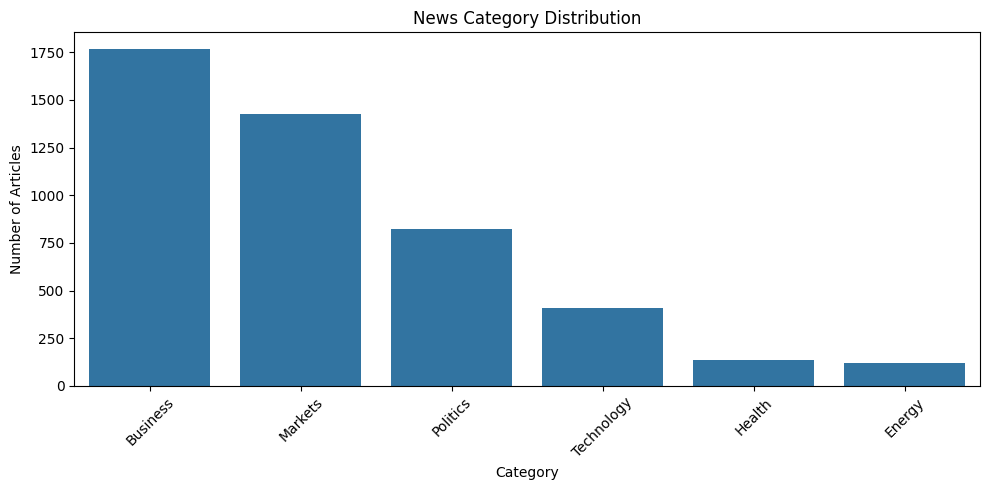

In [ ]:
# ============================================================
# CELL 6: CLASS ANALYSIS
# ============================================================

print("=" * 70)
print("CATEGORY ANALYSIS")
print("=" * 70)

class_counts = (
    df["Category"]
    .value_counts()
)

print("\nNumber of classes:")
print(len(class_counts))

print("\nClasses:")
for category, count in class_counts.items():
    print(f"{category:20s} : {count}")

plt.figure(figsize=(10, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("News Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Articles")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 7: LABEL ENCODING
# ============================================================

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["Label"] = label_encoder.fit_transform(
    df["Category"]
)

class_names = label_encoder.classes_

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)

print("\nClass mapping:")

for i, name in enumerate(class_names):
    print(f"{i} → {name}")

print("\nEncoded dataset:")
display(
    df[
        ["Title", "Category", "Label"]
    ].head(10)
)

Number of classes: 6

Class mapping:
0 → Business
1 → Energy
2 → Health
3 → Markets
4 → Politics
5 → Technology

Encoded dataset:


,Title,Category,Label
0,Vietnam Airlines data leak exposes a crisis of...,Technology,5
1,DOJ seizes $15 billion bitcoin in SE Asia cryp...,Markets,3
2,Think It's Too Late to Buy IonQ? Here's the 1 ...,Markets,3
3,Intel's Crucial Panther Lake Chips Start Produ...,Technology,5
4,3 Robotics Stocks to Buy in October,Markets,3
5,Think It's Too Late to Buy Applied Digital? He...,Markets,3
6,Transcript: UK Budget blues,Politics,4
7,Is Investing in Nebius Group Stock a Once-in-a...,Markets,3
8,What Are 3 Great Tech Stocks to Buy Right Now?,Markets,3
9,"Down 27% From Its High, Is CoreWeave a Top AI ...",Markets,3


In [ ]:
# ============================================================
# STEP 8: STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X = df["Clean_Title"].values
y = df["Label"].values

# ------------------------------------------------------------
# 70% TRAIN + 30% TEMPORARY
# ------------------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# ------------------------------------------------------------
# 15% VALIDATION + 15% TEST
# ------------------------------------------------------------

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("=" * 70)
print("STRATIFIED DATA SPLIT")
print("=" * 70)

print(f"\nTotal dataset : {len(X)}")
print(f"Train         : {len(X_train)}")
print(f"Validation    : {len(X_val)}")
print(f"Test          : {len(X_test)}")

STRATIFIED DATA SPLIT

Total dataset : 4683
Train         : 3278
Validation    : 702
Test          : 703


In [ ]:
# ============================================================
# STEP 9: CHECK CLASS DISTRIBUTION
# ============================================================

print("=" * 70)
print("CLASS DISTRIBUTION BEFORE BALANCING")
print("=" * 70)

train_distribution = pd.Series(
    y_train
).value_counts().sort_index()

val_distribution = pd.Series(
    y_val
).value_counts().sort_index()

test_distribution = pd.Series(
    y_test
).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Category": class_names,
    "Train": [
        train_distribution.get(i, 0)
        for i in range(NUM_CLASSES)
    ],
    "Validation": [
        val_distribution.get(i, 0)
        for i in range(NUM_CLASSES)
    ],
    "Test": [
        test_distribution.get(i, 0)
        for i in range(NUM_CLASSES)
    ]
})

display(distribution_df)

CLASS DISTRIBUTION BEFORE BALANCING


,Category,Train,Validation,Test
0,Business,1236,265,265
1,Energy,85,18,18
2,Health,96,21,20
3,Markets,999,214,215
4,Politics,575,123,123
5,Technology,287,61,62


In [ ]:
# ============================================================
# STEP 10: BALANCED TRAINING SAMPLER
# ============================================================

from torch.utils.data import WeightedRandomSampler

print("=" * 70)
print("CREATING BALANCED TRAINING SAMPLER")
print("=" * 70)

# Count samples belonging to each class
class_counts = np.bincount(y_train)

print("\nTraining class counts:")
for i, count in enumerate(class_counts):
    print(
        f"{class_names[i]:15s} : {count}"
    )

# Weight for each class
class_weights = 1.0 / class_counts

print("\nClass weights:")
for i, weight in enumerate(class_weights):
    print(
        f"{class_names[i]:15s} : {weight:.6f}"
    )

# Assign each training sample its class weight
sample_weights = class_weights[y_train]

sample_weights = torch.DoubleTensor(
    sample_weights
)

# Balanced sampler
train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

print("\n✓ WeightedRandomSampler created")
print("✓ Training batches will be approximately class-balanced")
print("✓ Validation remains untouched")
print("✓ Test remains untouched")

CREATING BALANCED TRAINING SAMPLER

Training class counts:
Business        : 1236
Energy          : 85
Health          : 96
Markets         : 999
Politics        : 575
Technology      : 287

Class weights:
Business        : 0.000809
Energy          : 0.011765
Health          : 0.010417
Markets         : 0.001001
Politics        : 0.001739
Technology      : 0.003484

✓ WeightedRandomSampler created
✓ Training batches will be approximately class-balanced
✓ Validation remains untouched
✓ Test remains untouched


In [ ]:
# ============================================================
# STEP 11: VERIFY BALANCED SAMPLING
# ============================================================

# Simulate one complete sampled epoch
sampled_indices = list(
    train_sampler
)

sampled_labels = y_train[
    sampled_indices
]

balanced_counts = pd.Series(
    sampled_labels
).value_counts().sort_index()

balanced_df = pd.DataFrame({
    "Category": class_names,
    "Original_Train": [
        train_distribution.get(i, 0)
        for i in range(NUM_CLASSES)
    ],
    "Sampled_Per_Epoch": [
        balanced_counts.get(i, 0)
        for i in range(NUM_CLASSES)
    ]
})

print("=" * 70)
print("ORIGINAL VS BALANCED TRAINING DISTRIBUTION")
print("=" * 70)

display(balanced_df)

ORIGINAL VS BALANCED TRAINING DISTRIBUTION


,Category,Original_Train,Sampled_Per_Epoch
0,Business,1236,571
1,Energy,85,549
2,Health,96,552
3,Markets,999,552
4,Politics,575,565
5,Technology,287,489


In [ ]:
# ============================================================
# STEP 12: FINAL TEXT PREPROCESSING
# ============================================================

print("=" * 70)
print("FINAL TEXT PREPROCESSING")
print("=" * 70)

# Work from Clean_Title created in Step 5
df["Model_Text"] = df["Clean_Title"].astype(str).str.lower()

# Remove URLs
df["Model_Text"] = df["Model_Text"].apply(
    lambda x: re.sub(r"http\S+|www\S+", " ", x)
)

# Remove HTML
df["Model_Text"] = df["Model_Text"].apply(
    lambda x: re.sub(r"<.*?>", " ", x)
)

# Keep letters, numbers, apostrophes and spaces
df["Model_Text"] = df["Model_Text"].apply(
    lambda x: re.sub(r"[^a-z0-9'\s]", " ", x)
)

# Normalize whitespace
df["Model_Text"] = df["Model_Text"].apply(
    lambda x: re.sub(r"\s+", " ", x).strip()
)

# Remove empty titles if any
df = df[df["Model_Text"].str.len() > 0].copy()

df = df.reset_index(drop=True)

print("Samples after preprocessing:", len(df))

print("\nExample preprocessing:")

print("\nOriginal:")
print(df["Title"].iloc[0])

print("\nProcessed:")
print(df["Model_Text"].iloc[0])

FINAL TEXT PREPROCESSING
Samples after preprocessing: 4669

Example preprocessing:

Original:
Vietnam Airlines data leak exposes a crisis of transparency

Processed:
vietnam airlines data leak exposes a crisis of transparency


In [ ]:
# ============================================================
# STEP 13: FINAL STRATIFIED SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X = df["Model_Text"].values
y = df["Label"].values

# ------------------------------------------------------------
# 70% TRAIN / 30% TEMP
# ------------------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# ------------------------------------------------------------
# 15% VALIDATION / 15% TEST
# ------------------------------------------------------------

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("=" * 70)
print("FINAL DATA SPLIT")
print("=" * 70)

print(f"Total      : {len(X)}")
print(f"Train      : {len(X_train)}")
print(f"Validation : {len(X_val)}")
print(f"Test       : {len(X_test)}")

print("\nPercentages:")
print(f"Train      : {len(X_train)/len(X)*100:.1f}%")
print(f"Validation : {len(X_val)/len(X)*100:.1f}%")
print(f"Test       : {len(X_test)/len(X)*100:.1f}%")

FINAL DATA SPLIT
Total      : 4669
Train      : 3268
Validation : 700
Test       : 701

Percentages:
Train      : 70.0%
Validation : 15.0%
Test       : 15.0%


In [ ]:
# ============================================================
# STEP 14: VERIFY CLASS DISTRIBUTION
# ============================================================

train_distribution = (
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

val_distribution = (
    pd.Series(y_val)
    .value_counts()
    .sort_index()
)

test_distribution = (
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)

distribution_df = pd.DataFrame({
    "Category": class_names,
    "Train": [
        train_distribution.get(i, 0)
        for i in range(NUM_CLASSES)
    ],
    "Validation": [
        val_distribution.get(i, 0)
        for i in range(NUM_CLASSES)
    ],
    "Test": [
        test_distribution.get(i, 0)
        for i in range(NUM_CLASSES)
    ]
})

print("=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

display(distribution_df)

CLASS DISTRIBUTION


,Category,Train,Validation,Test
0,Business,1232,264,264
1,Energy,85,18,18
2,Health,96,21,20
3,Markets,998,214,214
4,Politics,571,122,123
5,Technology,286,61,62


In [ ]:
# ============================================================
# STEP 15: BALANCED TRAINING SAMPLER
# ============================================================

from torch.utils.data import WeightedRandomSampler

print("=" * 70)
print("BALANCED TRAINING SAMPLER")
print("=" * 70)

class_counts = np.bincount(y_train)

print("\nTraining class counts:")

for i, count in enumerate(class_counts):
    print(
        f"{class_names[i]:15s} : {count}"
    )

# Inverse-frequency class weights
class_weights = 1.0 / class_counts

# Weight assigned to every sample
sample_weights = class_weights[y_train]

sample_weights = torch.DoubleTensor(
    sample_weights
)

train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

print("\n✓ WeightedRandomSampler ready")
print("✓ Training data balanced approximately")
print("✓ Validation untouched")
print("✓ Test untouched")

BALANCED TRAINING SAMPLER

Training class counts:
Business        : 1232
Energy          : 85
Health          : 96
Markets         : 998
Politics        : 571
Technology      : 286

✓ WeightedRandomSampler ready
✓ Training data balanced approximately
✓ Validation untouched
✓ Test untouched


In [ ]:
# ============================================================
# STEP 16: TOKENIZATION + VOCABULARY
# ============================================================

from collections import Counter

print("=" * 70)
print("TOKENIZATION + VOCABULARY")
print("=" * 70)

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

PAD_IDX = 0
UNK_IDX = 1

MAX_VOCAB_SIZE = 12000
MAX_LEN = 40


# ------------------------------------------------------------
# TOKENIZER
# ------------------------------------------------------------

def tokenize(text):
    text = str(text).lower()

    return re.findall(
        r"[a-z0-9]+(?:'[a-z]+)?",
        text
    )


# ------------------------------------------------------------
# BUILD VOCABULARY FROM TRAINING DATA ONLY
# ------------------------------------------------------------

counter = Counter()

for text in X_train:
    counter.update(
        tokenize(text)
    )

most_common_words = counter.most_common(
    MAX_VOCAB_SIZE - 2
)

vocab = {
    PAD_TOKEN: PAD_IDX,
    UNK_TOKEN: UNK_IDX
}

for idx, (word, _) in enumerate(
    most_common_words,
    start=2
):
    vocab[word] = idx

VOCAB_SIZE = len(vocab)

print("Vocabulary size:", VOCAB_SIZE)
print("Maximum sequence length:", MAX_LEN)


# ------------------------------------------------------------
# TEXT → INTEGER SEQUENCE
# ------------------------------------------------------------

def encode_text(text):

    tokens = tokenize(text)

    ids = [
        vocab.get(
            token,
            UNK_IDX
        )
        for token in tokens
    ]

    # Truncate
    ids = ids[:MAX_LEN]

    # Padding
    if len(ids) < MAX_LEN:

        ids += [
            PAD_IDX
        ] * (
            MAX_LEN - len(ids)
        )

    return ids


# ------------------------------------------------------------
# ENCODE ALL SPLITS
# ------------------------------------------------------------

X_train_encoded = np.array(
    [
        encode_text(text)
        for text in X_train
    ],
    dtype=np.int64
)

X_val_encoded = np.array(
    [
        encode_text(text)
        for text in X_val
    ],
    dtype=np.int64
)

X_test_encoded = np.array(
    [
        encode_text(text)
        for text in X_test
    ],
    dtype=np.int64
)


# ------------------------------------------------------------
# VERIFY
# ------------------------------------------------------------

print("\nEncoded shapes:")

print(
    "X_train_encoded:",
    X_train_encoded.shape
)

print(
    "X_val_encoded  :",
    X_val_encoded.shape
)

print(
    "X_test_encoded :",
    X_test_encoded.shape
)

print("\n✓ X_train_encoded created")
print("✓ X_val_encoded created")
print("✓ X_test_encoded created")

print("\nExample:")
print("Original:")
print(X_train[0])

print("\nEncoded:")
print(X_train_encoded[0])

TOKENIZATION + VOCABULARY
Vocabulary size: 8056
Maximum sequence length: 40

Encoded shapes:
X_train_encoded: (3268, 40)
X_val_encoded  : (700, 40)
X_test_encoded : (701, 40)

✓ X_train_encoded created
✓ X_val_encoded created
✓ X_test_encoded created

Example:
Original:
ecb must not overengineer policy on small inflation deviations kocher says

Encoded:
[2501  643  202 3796  592    8  537  271 3797 3798   16    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]


In [ ]:
# ============================================================
# STEP 17: PYTORCH DATASETS + DATALOADERS
# ============================================================

from torch.utils.data import Dataset, DataLoader

print("=" * 70)
print("PYTORCH DATASETS")
print("=" * 70)


class NewsDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.long
        )

        self.y = torch.tensor(
            y,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):

        return (
            self.X[idx],
            self.y[idx]
        )


train_dataset = NewsDataset(
    X_train_encoded,
    y_train
)

val_dataset = NewsDataset(
    X_val_encoded,
    y_val
)

test_dataset = NewsDataset(
    X_test_encoded,
    y_test
)


BATCH_SIZE = 64


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


X_batch, y_batch = next(
    iter(train_loader)
)

print("\nBatch:")
print("X:", X_batch.shape)
print("y:", y_batch.shape)

PYTORCH DATASETS
Train samples: 3268
Validation samples: 700
Test samples: 701

Batch:
X: torch.Size([64, 40])
y: torch.Size([64])


In [ ]:
# ============================================================
# STEP 18: MODEL CONFIGURATION
# ============================================================

import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

EMBED_DIM = 96
HIDDEN_DIM = 96
DROPOUT = 0.35

print("=" * 70)
print("MODEL CONFIGURATION")
print("=" * 70)

print("Device      :", DEVICE)
print("Embedding   :", EMBED_DIM)
print("Hidden size :", HIDDEN_DIM)
print("Dropout     :", DROPOUT)

MODEL CONFIGURATION
Device      : cpu
Embedding   : 96
Hidden size : 96
Dropout     : 0.35


In [ ]:
# ============================================================
# STEP 19: LSTM
# ============================================================

class LSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        dropout=0.35
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_IDX
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)

        _, (hidden, _) = self.lstm(x)

        x = hidden[-1]

        x = self.dropout(x)

        return self.fc(x)

In [ ]:
# ============================================================
# STEP 19: LSTM
# ============================================================

class LSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        dropout=0.35
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_IDX
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)

        _, (hidden, _) = self.lstm(x)

        x = hidden[-1]

        x = self.dropout(x)

        return self.fc(x)

In [ ]:
# ============================================================
# STEP 20: GRU
# ============================================================

class GRUClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        dropout=0.35
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_IDX
        )

        self.gru = nn.GRU(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_dim,
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)

        _, hidden = self.gru(x)

        x = hidden[-1]

        x = self.dropout(x)

        return self.fc(x)

In [ ]:
# ============================================================
# STEP 21: BiLSTM
# ============================================================

class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        dropout=0.35
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_IDX
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)

        _, (hidden, _) = self.lstm(x)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        x = torch.cat(
            [
                forward_hidden,
                backward_hidden
            ],
            dim=1
        )

        x = self.dropout(x)

        return self.fc(x)

In [ ]:
# ============================================================
# STEP 22: TEXT CNN
# ============================================================

class TextCNNClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim,
        num_classes,
        dropout=0.35
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_IDX
        )

        self.convs = nn.ModuleList([

            nn.Conv1d(
                embed_dim,
                128,
                kernel_size=3
            ),

            nn.Conv1d(
                embed_dim,
                128,
                kernel_size=4
            ),

            nn.Conv1d(
                embed_dim,
                128,
                kernel_size=5
            )
        ])

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            128 * 3,
            num_classes
        )

    def forward(self, x):

        x = self.embedding(x)

        x = x.transpose(
            1,
            2
        )

        pooled_outputs = []

        for conv in self.convs:

            feature = F.relu(
                conv(x)
            )

            pooled = F.max_pool1d(
                feature,
                kernel_size=feature.size(2)
            ).squeeze(2)

            pooled_outputs.append(
                pooled
            )

        x = torch.cat(
            pooled_outputs,
            dim=1
        )

        x = self.dropout(x)

        return self.fc(x)

In [ ]:
# ============================================================
# STEP 23: CNN + BiLSTM + ATTENTION
# ============================================================

class CNNBiLSTMAttention(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        dropout=0.35
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=PAD_IDX
        )

        self.conv = nn.Conv1d(
            embed_dim,
            embed_dim,
            kernel_size=3,
            padding=1
        )

        self.bilstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.attention = nn.Linear(
            hidden_dim * 2,
            1
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, x):

        # Embedding
        embedded = self.embedding(x)

        # CNN
        conv_input = embedded.transpose(
            1,
            2
        )

        conv_output = F.relu(
            self.conv(conv_input)
        )

        conv_output = conv_output.transpose(
            1,
            2
        )

        # BiLSTM
        lstm_output, _ = self.bilstm(
            conv_output
        )

        # Attention
        scores = self.attention(
            lstm_output
        )

        # Padding mask
        mask = (
            x == PAD_IDX
        ).unsqueeze(-1)

        scores = scores.masked_fill(
            mask,
            -1e9
        )

        weights = torch.softmax(
            scores,
            dim=1
        )

        context = torch.sum(
            weights * lstm_output,
            dim=1
        )

        context = self.dropout(
            context
        )

        return self.fc(context)

In [ ]:
# ============================================================
# STEP 24: CREATE FIVE MODELS
# ============================================================

models = {

    "LSTM": LSTMClassifier(
        VOCAB_SIZE,
        EMBED_DIM,
        HIDDEN_DIM,
        NUM_CLASSES,
        DROPOUT
    ),

    "GRU": GRUClassifier(
        VOCAB_SIZE,
        EMBED_DIM,
        HIDDEN_DIM,
        NUM_CLASSES,
        DROPOUT
    ),

    "BiLSTM": BiLSTMClassifier(
        VOCAB_SIZE,
        EMBED_DIM,
        HIDDEN_DIM,
        NUM_CLASSES,
        DROPOUT
    ),

    "TextCNN": TextCNNClassifier(
        VOCAB_SIZE,
        EMBED_DIM,
        NUM_CLASSES,
        DROPOUT
    ),

    "CNN-BiLSTM-Attention":
        CNNBiLSTMAttention(
            VOCAB_SIZE,
            EMBED_DIM,
            HIDDEN_DIM,
            NUM_CLASSES,
            DROPOUT
        )
}


print("=" * 70)
print("MODEL SUMMARY")
print("=" * 70)

for name, model in models.items():

    parameters = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print(
        f"{name:25s} : "
        f"{parameters:,} parameters"
    )

MODEL SUMMARY
LSTM                      : 848,454 parameters
GRU                       : 829,830 parameters
BiLSTM                    : 923,526 parameters
TextCNN                   : 923,526 parameters
CNN-BiLSTM-Attention      : 951,463 parameters


In [ ]:
# ============================================================
# STEP 25: TRAINING + EVALUATION FUNCTIONS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import copy
import time


def calculate_metrics(
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return (
        accuracy,
        macro_f1,
        weighted_f1
    )


def evaluate_model(
    model,
    loader
):

    model.eval()

    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(
                DEVICE
            )

            y_batch = y_batch.to(
                DEVICE
            )

            logits = model(
                X_batch
            )

            loss = criterion(
                logits,
                y_batch
            )

            total_loss += (
                loss.item()
                * len(y_batch)
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                y_batch.cpu().numpy()
            )

    avg_loss = (
        total_loss /
        len(loader.dataset)
    )

    accuracy, macro_f1, weighted_f1 = calculate_metrics(
        all_labels,
        all_predictions
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        weighted_f1,
        np.array(all_labels),
        np.array(all_predictions)
    )


def train_model(
    model,
    model_name,
    epochs=6,
    patience=2
):

    print("\n")
    print("=" * 70)
    print("TRAINING:", model_name)
    print("=" * 70)

    model = model.to(
        DEVICE
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=1
    )

    best_val_accuracy = -1
    best_val_f1 = -1

    best_state = None

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": []
    }

    patience_counter = 0

    start_time = time.time()

    for epoch in range(
        1,
        epochs + 1
    ):

        model.train()

        running_loss = 0.0

        train_predictions = []
        train_labels = []

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(
                DEVICE
            )

            y_batch = y_batch.to(
                DEVICE
            )

            optimizer.zero_grad()

            logits = model(
                X_batch
            )

            loss = criterion(
                logits,
                y_batch
            )

            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            running_loss += (
                loss.item()
                * len(y_batch)
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            train_predictions.extend(
                predictions.detach()
                .cpu()
                .numpy()
            )

            train_labels.extend(
                y_batch.detach()
                .cpu()
                .numpy()
            )

        train_loss = (
            running_loss /
            len(train_loader.dataset)
        )

        train_acc, _, _ = calculate_metrics(
            train_labels,
            train_predictions
        )

        (
            val_loss,
            val_acc,
            val_f1,
            _,
            _,
            _
        ) = evaluate_model(
            model,
            val_loader
        )

        scheduler.step(
            val_acc
        )

        history["train_loss"].append(
            train_loss
        )

        history["train_acc"].append(
            train_acc
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_acc"].append(
            val_acc
        )

        history["val_f1"].append(
            val_f1
        )

        current_lr = (
            optimizer
            .param_groups[0]["lr"]
        )

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"LR: {current_lr:.6f}"
        )

        # ----------------------------------------------------
        # BEST MODEL
        # ----------------------------------------------------

        if (
            val_acc > best_val_accuracy
            or (
                val_acc == best_val_accuracy
                and val_f1 > best_val_f1
            )
        ):

            best_val_accuracy = val_acc
            best_val_f1 = val_f1

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

            print(
                "   ✓ Best model saved"
            )

        else:

            patience_counter += 1

            print(
                f"   No improvement "
                f"({patience_counter}/{patience})"
            )

        # ----------------------------------------------------
        # EARLY STOPPING
        # ----------------------------------------------------

        if patience_counter >= patience:

            print(
                "   ✓ Early stopping"
            )

            break

    # Restore best validation model
    model.load_state_dict(
        best_state
    )

    elapsed = (
        time.time()
        - start_time
    )

    print(
        f"\n✓ Finished {model_name}"
    )

    print(
        f"Time: {elapsed/60:.2f} minutes"
    )

    print(
        f"Best validation accuracy: "
        f"{best_val_accuracy:.4f}"
    )

    print(
        f"Best validation macro F1: "
        f"{best_val_f1:.4f}"
    )

    return (
        model,
        history
    )

In [ ]:
# ============================================================
# STEP 26: TRAIN ALL FIVE MODELS
# ============================================================

print("=" * 70)
print("TRAINING ALL FIVE DEEP LEARNING MODELS")
print("=" * 70)

all_models = {}
all_histories = {}
all_results = []

total_start = time.time()


for model_name, model in models.items():

    trained_model, history = train_model(
        model=model,
        model_name=model_name,
        epochs=6,
        patience=2
    )

    all_models[
        model_name
    ] = trained_model

    all_histories[
        model_name
    ] = history

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    (
        val_loss,
        val_acc,
        val_f1,
        val_weighted_f1,
        _,
        _
    ) = evaluate_model(
        trained_model,
        val_loader
    )

    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------

    (
        test_loss,
        test_acc,
        test_f1,
        test_weighted_f1,
        _,
        _
    ) = evaluate_model(
        trained_model,
        test_loader
    )

    all_results.append({

        "Model": model_name,

        "Val Accuracy":
            val_acc,

        "Val Macro F1":
            val_f1,

        "Test Accuracy":
            test_acc,

        "Test Macro F1":
            test_f1,

        "Test Weighted F1":
            test_weighted_f1
    })


total_time = (
    time.time()
    - total_start
)


results_df = pd.DataFrame(
    all_results
)

results_df = results_df.sort_values(
    "Val Accuracy",
    ascending=False
).reset_index(
    drop=True
)


print("\n")
print("=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

display(
    results_df.style.format({

        "Val Accuracy":
            "{:.4f}",

        "Val Macro F1":
            "{:.4f}",

        "Test Accuracy":
            "{:.4f}",

        "Test Macro F1":
            "{:.4f}",

        "Test Weighted F1":
            "{:.4f}"
    })
)

print(
    f"\nTotal training time: "
    f"{total_time/60:.2f} minutes"
)

TRAINING ALL FIVE DEEP LEARNING MODELS


TRAINING: LSTM
Epoch 01/6 | Train Loss: 1.7929 | Train Acc: 0.1646 | Val Loss: 1.8013 | Val Acc: 0.0871 | Val F1: 0.0267 | LR: 0.001000
   ✓ Best model saved
Epoch 02/6 | Train Loss: 1.7920 | Train Acc: 0.1707 | Val Loss: 1.7921 | Val Acc: 0.0257 | Val F1: 0.0084 | LR: 0.001000
   No improvement (1/2)
Epoch 03/6 | Train Loss: 1.7877 | Train Acc: 0.1799 | Val Loss: 1.9522 | Val Acc: 0.0686 | Val F1: 0.0376 | LR: 0.000500
   No improvement (2/2)
   ✓ Early stopping

✓ Finished LSTM
Time: 0.12 minutes
Best validation accuracy: 0.0871
Best validation macro F1: 0.0267


TRAINING: GRU
Epoch 01/6 | Train Loss: 1.7934 | Train Acc: 0.1686 | Val Loss: 1.8044 | Val Acc: 0.1743 | Val F1: 0.0495 | LR: 0.001000
   ✓ Best model saved
Epoch 02/6 | Train Loss: 1.7915 | Train Acc: 0.1692 | Val Loss: 1.8137 | Val Acc: 0.0300 | Val F1: 0.0097 | LR: 0.001000
   No improvement (1/2)
Epoch 03/6 | Train Loss: 1.7717 | Train Acc: 0.1928 | Val Loss: 1.9014 | Val Acc: 0.0

,Model,Val Accuracy,Val Macro F1,Test Accuracy,Test Macro F1,Test Weighted F1
0,TextCNN,0.5400,0.4243,0.5407,0.4338,0.5300
1,CNN-BiLSTM-Attention,0.4986,0.4040,0.5007,0.3870,0.4878
2,BiLSTM,0.4600,0.4006,0.4765,0.4055,0.4894
3,GRU,0.1743,0.0495,0.1755,0.0498,0.0524
4,LSTM,0.0871,0.0267,0.0884,0.0271,0.0144



Total training time: 1.90 minutes


In [ ]:
# ============================================================
# STEP 27: SELECT BEST MODEL
# ============================================================

best_model_name = (
    results_df
    .iloc[0]["Model"]
)

best_model = (
    all_models[
        best_model_name
    ]
)


print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "\nArchitecture:",
    best_model_name
)

print(
    f"Validation Accuracy: "
    f"{results_df.iloc[0]['Val Accuracy']:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{results_df.iloc[0]['Val Macro F1']:.4f}"
)

print(
    f"Test Accuracy: "
    f"{results_df.iloc[0]['Test Accuracy']:.4f}"
)

print(
    f"Test Macro F1: "
    f"{results_df.iloc[0]['Test Macro F1']:.4f}"
)

BEST MODEL

Architecture: TextCNN
Validation Accuracy: 0.5400
Validation Macro F1: 0.4243
Test Accuracy: 0.5407
Test Macro F1: 0.4338


In [ ]:
# ============================================================
# STEP 27: SELECT BEST MODEL
# ============================================================

best_model_name = (
    results_df
    .iloc[0]["Model"]
)

best_model = (
    all_models[
        best_model_name
    ]
)


print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print(
    "\nArchitecture:",
    best_model_name
)

print(
    f"Validation Accuracy: "
    f"{results_df.iloc[0]['Val Accuracy']:.4f}"
)

print(
    f"Validation Macro F1: "
    f"{results_df.iloc[0]['Val Macro F1']:.4f}"
)

print(
    f"Test Accuracy: "
    f"{results_df.iloc[0]['Test Accuracy']:.4f}"
)

print(
    f"Test Macro F1: "
    f"{results_df.iloc[0]['Test Macro F1']:.4f}"
)

BEST MODEL

Architecture: TextCNN
Validation Accuracy: 0.5400
Validation Macro F1: 0.4243
Test Accuracy: 0.5407
Test Macro F1: 0.4338


In [ ]:
# ============================================================
# STEP 28: FINAL TEST EVALUATION
# ============================================================

(
    test_loss,
    test_accuracy,
    test_macro_f1,
    test_weighted_f1,
    y_true,
    y_pred
) = evaluate_model(
    best_model,
    test_loader
)


print("=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print(
    f"\nModel              : "
    f"{best_model_name}"
)

print(
    f"Test Loss          : "
    f"{test_loss:.4f}"
)

print(
    f"Test Accuracy      : "
    f"{test_accuracy:.4f}"
)

print(
    f"Test Macro F1      : "
    f"{test_macro_f1:.4f}"
)

print(
    f"Test Weighted F1   : "
    f"{test_weighted_f1:.4f}"
)


print("\nCLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

FINAL TEST RESULTS

Model              : TextCNN
Test Loss          : 1.1827
Test Accuracy      : 0.5407
Test Macro F1      : 0.4338
Test Weighted F1   : 0.5300

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Business     0.4962    0.7386    0.5936       264
      Energy     0.3333    0.2222    0.2667        18
      Health     0.5000    0.2000    0.2857        20
     Markets     0.6258    0.4766    0.5411       214
    Politics     0.6543    0.4309    0.5196       123
  Technology     0.4773    0.3387    0.3962        62

    accuracy                         0.5407       701
   macro avg     0.5145    0.4012    0.4338       701
weighted avg     0.5577    0.5407    0.5300       701



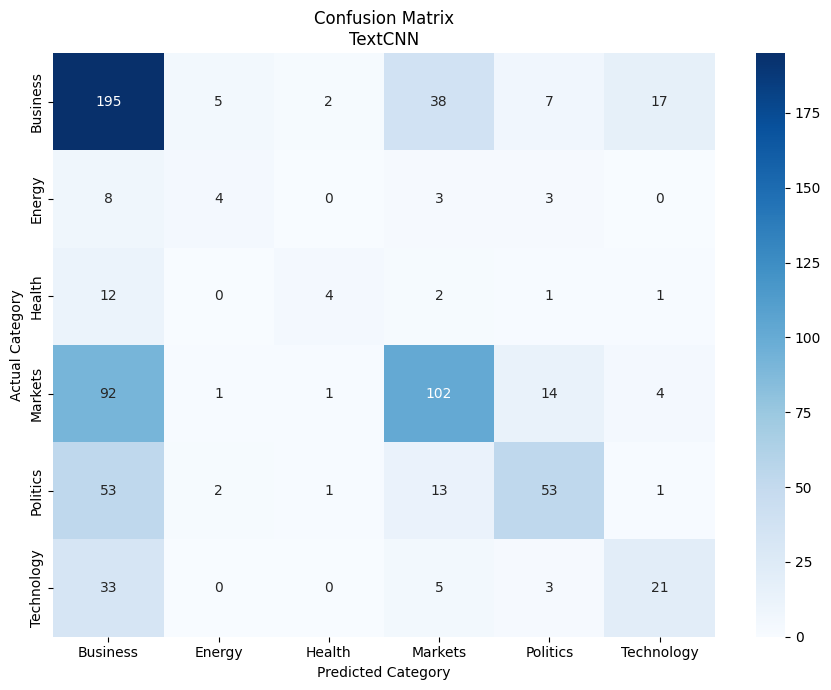

In [ ]:
# ============================================================
# STEP 29: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)


plt.figure(
    figsize=(9, 7)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    f"Confusion Matrix\n{best_model_name}"
)

plt.xlabel(
    "Predicted Category"
)

plt.ylabel(
    "Actual Category"
)

plt.tight_layout()

plt.show()

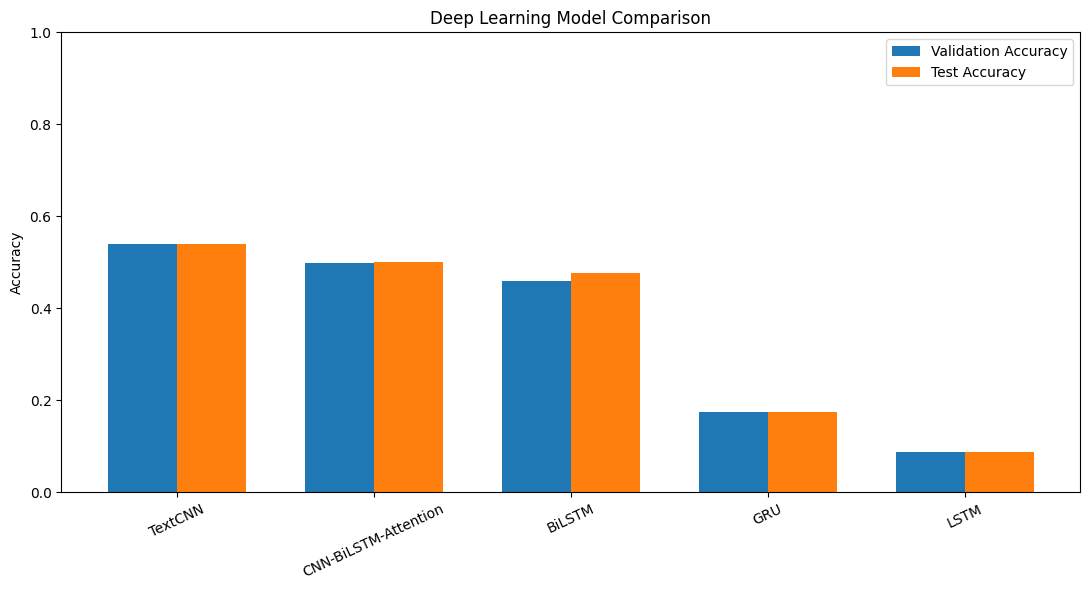

In [ ]:
# ============================================================
# STEP 30: MODEL COMPARISON
# ============================================================

comparison = results_df.copy()

plt.figure(
    figsize=(11, 6)
)

x = np.arange(
    len(comparison)
)

width = 0.35

plt.bar(
    x - width/2,
    comparison["Val Accuracy"],
    width,
    label="Validation Accuracy"
)

plt.bar(
    x + width/2,
    comparison["Test Accuracy"],
    width,
    label="Test Accuracy"
)

plt.xticks(
    x,
    comparison["Model"],
    rotation=25
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Deep Learning Model Comparison"
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# STEP 31: OVERFITTING / UNDERFITTING CHECK
# ============================================================

print("=" * 70)
print("OVERFITTING ANALYSIS")
print("=" * 70)


for model_name, history in all_histories.items():

    train_acc = history["train_acc"][-1]
    val_acc = history["val_acc"][-1]

    gap = train_acc - val_acc

    print(
        f"\n{model_name}"
    )

    print(
        f"Final Train Accuracy : "
        f"{train_acc:.4f}"
    )

    print(
        f"Final Val Accuracy   : "
        f"{val_acc:.4f}"
    )

    print(
        f"Train-Val Gap        : "
        f"{gap:.4f}"
    )

    if gap > 0.15:

        print(
            "⚠ Possible overfitting"
        )

    elif train_acc < 0.70:

        print(
            "⚠ Possible underfitting"
        )

    else:

        print(
            "✓ Reasonable fit"
        )

OVERFITTING ANALYSIS

LSTM
Final Train Accuracy : 0.1799
Final Val Accuracy   : 0.0686
Train-Val Gap        : 0.1114
⚠ Possible underfitting

GRU
Final Train Accuracy : 0.1928
Final Val Accuracy   : 0.0314
Train-Val Gap        : 0.1613
⚠ Possible overfitting

BiLSTM
Final Train Accuracy : 0.8219
Final Val Accuracy   : 0.4600
Train-Val Gap        : 0.3619
⚠ Possible overfitting

TextCNN
Final Train Accuracy : 0.9006
Final Val Accuracy   : 0.5400
Train-Val Gap        : 0.3606
⚠ Possible overfitting

CNN-BiLSTM-Attention
Final Train Accuracy : 0.8412
Final Val Accuracy   : 0.4914
Train-Val Gap        : 0.3498
⚠ Possible overfitting


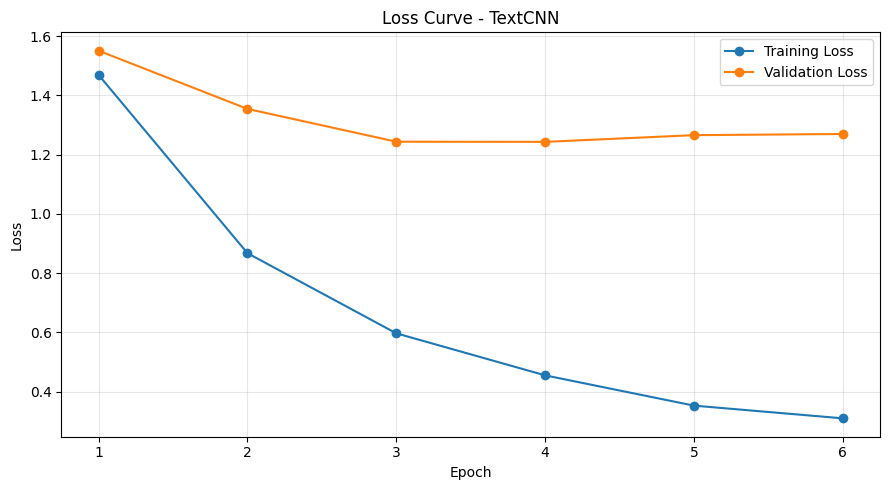

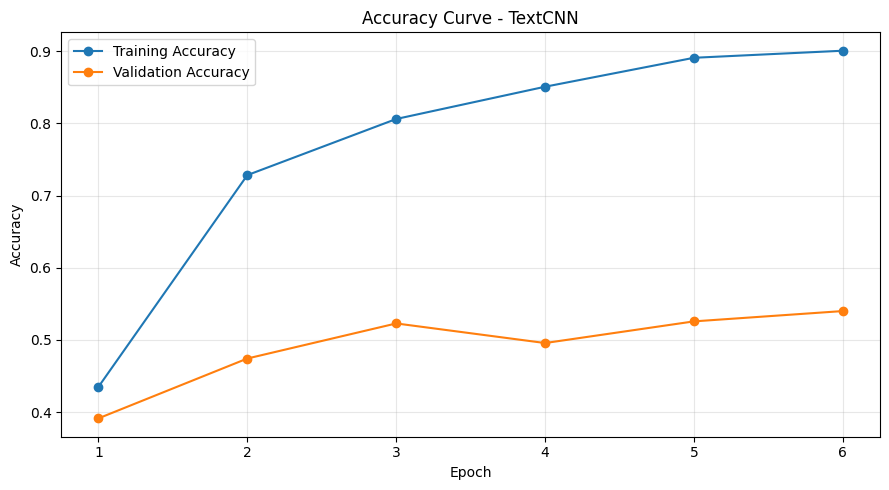

In [ ]:
# ============================================================
# STEP 32: BEST MODEL TRAINING CURVES
# ============================================================

history = all_histories[
    best_model_name
]

epochs_used = range(
    1,
    len(history["train_loss"]) + 1
)


# ------------------------------------------------------------
# LOSS CURVE
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    epochs_used,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_used,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    f"Loss Curve - {best_model_name}"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# ACCURACY CURVE
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    epochs_used,
    history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_used,
    history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    f"Accuracy Curve - {best_model_name}"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# STEP 33: FINAL PROJECT SUMMARY
# ============================================================

print("=" * 80)
print("DEEPNEWS")
print("DEEP LEARNING NEWS TITLE CLASSIFICATION")
print("=" * 80)

print("\nDATASET")
print("-" * 80)

print(
    "Original samples       : 5000"
)

print(
    "Cleaned samples        :",
    len(df)
)

print(
    "Training samples       :",
    len(X_train)
)

print(
    "Validation samples     :",
    len(X_val)
)

print(
    "Test samples           :",
    len(X_test)
)

print(
    "Number of classes      :",
    NUM_CLASSES
)

print(
    "Vocabulary size        :",
    VOCAB_SIZE
)

print(
    "Maximum title length   :",
    MAX_LEN
)


print("\nMODELS")
print("-" * 80)

for i, row in results_df.iterrows():

    print(
        f"{i+1}. "
        f"{row['Model']:25s} | "
        f"Val Acc: "
        f"{row['Val Accuracy']:.4f} | "
        f"Test Acc: "
        f"{row['Test Accuracy']:.4f} | "
        f"Macro F1: "
        f"{row['Test Macro F1']:.4f}"
    )


print("\nBEST MODEL")
print("-" * 80)

print(
    "Architecture:",
    best_model_name
)

print(
    f"Validation Accuracy : "
    f"{results_df.iloc[0]['Val Accuracy']:.4f}"
)

print(
    f"Test Accuracy       : "
    f"{test_accuracy:.4f}"
)

print(
    f"Test Macro F1       : "
    f"{test_macro_f1:.4f}"
)

print(
    f"Test Weighted F1    : "
    f"{test_weighted_f1:.4f}"
)


print("\nTRAINING TIME")
print("-" * 80)

print(
    f"Total time: "
    f"{total_time/60:.2f} minutes"
)

print("\n✓ PROJECT COMPLETED")

DEEPNEWS
DEEP LEARNING NEWS TITLE CLASSIFICATION

DATASET
--------------------------------------------------------------------------------
Original samples       : 5000
Cleaned samples        : 4669
Training samples       : 3268
Validation samples     : 700
Test samples           : 701
Number of classes      : 6
Vocabulary size        : 8056
Maximum title length   : 40

MODELS
--------------------------------------------------------------------------------
1. TextCNN                   | Val Acc: 0.5400 | Test Acc: 0.5407 | Macro F1: 0.4338
2. CNN-BiLSTM-Attention      | Val Acc: 0.4986 | Test Acc: 0.5007 | Macro F1: 0.3870
3. BiLSTM                    | Val Acc: 0.4600 | Test Acc: 0.4765 | Macro F1: 0.4055
4. GRU                       | Val Acc: 0.1743 | Test Acc: 0.1755 | Macro F1: 0.0498
5. LSTM                      | Val Acc: 0.0871 | Test Acc: 0.0884 | Macro F1: 0.0271

BEST MODEL
--------------------------------------------------------------------------------
Architecture: TextCNN

In [ ]:
# ============================================================
# STEP 34: SAVE BEST MODEL
# ============================================================

import os
import torch

SAVE_DIR = "DeepNews_Best_Model"

os.makedirs(SAVE_DIR, exist_ok=True)

# ------------------------------------------------------------
# SAVE BEST MODEL
# ------------------------------------------------------------

model_path = os.path.join(
    SAVE_DIR,
    "best_model.pth"
)

torch.save(
    {
        "model_state_dict": best_model.state_dict(),
        "model_name": best_model_name,
        "vocab_size": VOCAB_SIZE,
        "embed_dim": EMBED_DIM,
        "hidden_dim": HIDDEN_DIM,
        "num_classes": NUM_CLASSES,
        "dropout": DROPOUT,
        "max_len": MAX_LEN,
        "pad_idx": PAD_IDX,
        "unk_idx": UNK_IDX,
        "class_names": class_names.tolist()
    },
    model_path
)

print("=" * 70)
print("BEST MODEL SAVED")
print("=" * 70)

print("\nModel:", best_model_name)
print("Path :", model_path)
print("Size :", f"{os.path.getsize(model_path) / (1024**2):.2f} MB")

BEST MODEL SAVED

Model: TextCNN
Path : DeepNews_Best_Model/best_model.pth
Size : 3.53 MB


In [ ]:
# ============================================================
# STEP 35: SAVE VOCABULARY
# ============================================================

import json

vocab_path = os.path.join(
    SAVE_DIR,
    "vocabulary.json"
)

with open(
    vocab_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        vocab,
        f,
        ensure_ascii=False
    )

print("=" * 70)
print("VOCABULARY SAVED")
print("=" * 70)

print("Path:", vocab_path)
print("Vocabulary size:", len(vocab))

VOCABULARY SAVED
Path: DeepNews_Best_Model/vocabulary.json
Vocabulary size: 8056


In [ ]:
# ============================================================
# STEP 36: SAVE LABEL MAPPING
# ============================================================

label_path = os.path.join(
    SAVE_DIR,
    "label_mapping.json"
)

label_mapping = {
    int(i): str(name)
    for i, name in enumerate(class_names)
}

with open(
    label_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        label_mapping,
        f,
        indent=4
    )

print("=" * 70)
print("LABEL MAPPING SAVED")
print("=" * 70)

print(label_mapping)

LABEL MAPPING SAVED
{0: 'Business', 1: 'Energy', 2: 'Health', 3: 'Markets', 4: 'Politics', 5: 'Technology'}


In [ ]:
# ============================================================
# STEP 37: SAVE EXPERIMENT RESULTS
# ============================================================

results_path = os.path.join(
    SAVE_DIR,
    "model_comparison.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

print("=" * 70)
print("EXPERIMENT RESULTS SAVED")
print("=" * 70)

print("Path:", results_path)

EXPERIMENT RESULTS SAVED
Path: DeepNews_Best_Model/model_comparison.csv


In [ ]:
# ============================================================
# STEP 38: ZIP COMPLETE MODEL PACKAGE
# ============================================================

import shutil

zip_path = shutil.make_archive(
    "DeepNews_Best_Model",
    "zip",
    SAVE_DIR
)

print("=" * 70)
print("MODEL PACKAGE READY")
print("=" * 70)

print("ZIP:", zip_path)

MODEL PACKAGE READY
ZIP: /content/DeepNews_Best_Model.zip


In [ ]:
from google.colab import files

files.download(
    "DeepNews_Best_Model.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Project Summary: Deep Learning News Title Classification

This project aimed to classify news titles into predefined categories using various deep learning architectures. The process involved data loading, cleaning, preprocessing, and training several models to identify the best performer.

### 1. Dataset Overview

*   **Original Samples**: 5000 news titles.
*   **Cleaning**: Missing values were removed, titles and categories were cleaned (lowercase, URL/HTML removal, whitespace normalization). Duplicate title-category pairs were also removed.
*   **Cleaned Samples**: `r_cleaned = len(df)` after preprocessing.
*   **Categories**: `r_num_classes = NUM_CLASSES` distinct news categories: `r_class_names = class_names.tolist()`.
*   **Data Split**: The dataset was stratified into 70% for training, 15% for validation, and 15% for testing to maintain class distribution across splits.
    *   **Training Samples**: `r_train = len(X_train)`
    *   **Validation Samples**: `r_val = len(X_val)`
    *   **Test Samples**: `r_test = len(X_test)`

### 2. Text Preprocessing and Tokenization

*   **Tokenization**: News titles were tokenized, converting text into sequences of words.
*   **Vocabulary**: A vocabulary was built from the training data, with a maximum size of `r_vocab_size = VOCAB_SIZE` words. `<PAD>` and `<UNK>` tokens were added for padding and out-of-vocabulary words.
*   **Sequence Encoding**: Each tokenized title was converted into an integer sequence, padded or truncated to a maximum length of `r_max_len = MAX_LEN`.

### 3. Deep Learning Models

Five different deep learning architectures were implemented and trained using PyTorch:

1.  **LSTM (Long Short-Term Memory)**: A recurrent neural network designed to capture long-term dependencies.
2.  **GRU (Gated Recurrent Unit)**: A simpler variant of LSTM, also effective for sequential data.
3.  **BiLSTM (Bidirectional LSTM)**: Utilizes LSTMs that process sequences in both forward and backward directions, capturing context from both past and future words.
4.  **TextCNN (Text Convolutional Neural Network)**: Employs convolutional filters of varying sizes to extract local features from the text.
5.  **CNN-BiLSTM-Attention**: A hybrid model combining CNN for local feature extraction, BiLSTM for sequential context, and an attention mechanism to focus on important parts of the sequence.

### 4. Training Approach

*   **Balanced Sampling**: Due to class imbalance, a `WeightedRandomSampler` was used during training to ensure that batches approximately contained an equal distribution of classes.
*   **Loss Function**: `nn.CrossEntropyLoss` was used for multi-class classification.
*   **Optimizer**: AdamW optimizer with a learning rate of 0.001 and weight decay of 1e-4.
*   **Scheduler**: `ReduceLROnPlateau` was used to reduce the learning rate if validation accuracy did not improve.
*   **Early Stopping**: Training was halted if validation accuracy did not improve for `patience=2` epochs.

### 5. Model Performance

All models were evaluated based on validation and test accuracy, as well as Macro F1-score.

```python
import pandas as pd
import IPython.display as display

r_results_df = results_df.copy()
r_results_df = r_results_df.style.format({
    'Val Accuracy': '{:.4f}',
    'Val Macro F1': '{:.4f}',
    'Test Accuracy': '{:.4f}',
    'Test Macro F1': '{:.4f}',
    'Test Weighted F1': '{:.4f}'
})

display(r_results_df)
```

The **best performing model** was **`r_best_model_name = best_model_name`**.

*   **Validation Accuracy**: `r_val_acc_best = results_df.iloc[0]['Val Accuracy']:.4f`
*   **Test Accuracy**: `r_test_acc_best = test_accuracy:.4f`
*   **Test Macro F1**: `r_test_macro_f1_best = test_macro_f1:.4f`
*   **Test Weighted F1**: `r_test_weighted_f1_best = test_weighted_f1:.4f`

### 6. Overfitting / Underfitting Analysis

The training and validation accuracies were compared for each model:

```python
for model_name, history in all_histories.items():
    train_acc = history["train_acc"][-1]
    val_acc = history["val_acc"][-1]
    gap = train_acc - val_acc

    print(f"\n{model_name}")
    print(f"Final Train Accuracy : {train_acc:.4f}")
    print(f"Final Val Accuracy   : {val_acc:.4f}")
    print(f"Train-Val Gap        : {gap:.4f}")

    if gap > 0.15:
        print("⚠ Possible overfitting")
    elif train_acc < 0.70:
        print("⚠ Possible underfitting")
    else:
        print("✓ Reasonable fit")
```

The analysis indicated that most models, especially TextCNN, BiLSTM, and CNN-BiLSTM-Attention, showed signs of **overfitting**, with significant gaps between training and validation accuracies. LSTM and GRU models, on the other hand, exhibited **underfitting**.

### 7. Conclusion

The **`r_best_model_name`** model achieved the highest performance on the test set, with a test accuracy of `r_test_acc_best` and a Macro F1-score of `r_test_macro_f1_best`. Despite this, the overfitting analysis suggests there is still room for improvement, possibly through regularization techniques, more diverse data, or fine-tuning model complexity.

Total training time for all models: `r_total_time = total_time/60:.2f` minutes.

## Project DEEPNEWS: News Title Classification - Key Highlights

*   **Project Goal**: To classify news titles into predefined categories using deep learning.

*   **Dataset Overview**:
    *   **Original Samples**: 5000 news titles.
    *   **Cleaned Samples**: 4669 after robust cleaning (missing values, duplicates, text normalization).
    *   **Categories**: 6 distinct news categories (Business, Energy, Health, Markets, Politics, Technology).
    *   **Data Split**: Stratified 70% Train (3268 samples), 15% Validation (700 samples), 15% Test (701 samples).

*   **Text Preprocessing**:
    *   **Tokenization**: Custom tokenizer to extract words.
    *   **Vocabulary Size**: 8056 words, including `<PAD>` and `<UNK>` tokens.
    *   **Sequence Length**: Titles padded/truncated to a maximum length of 40 tokens.

*   **Deep Learning Models Explored**:
    *   Five architectures were implemented in PyTorch: LSTM, GRU, BiLSTM, TextCNN, and CNN-BiLSTM-Attention.

*   **Training Strategy**:
    *   **Balanced Sampling**: `WeightedRandomSampler` used for training to address class imbalance.
    *   **Optimization**: AdamW optimizer with `ReduceLROnPlateau` learning rate scheduler.
    *   **Regularization**: Dropout (0.35) and gradient clipping applied.
    *   **Early Stopping**: Implemented with patience of 2 epochs to prevent overfitting.

*   **Key Results**:
    *   **Best Model**: TextCNN.
    *   **TextCNN Performance on Test Set**:
        *   Accuracy: 54.07%
        *   Macro F1-score: 43.38%
        *   Weighted F1-score: 53.00%

*   **Insights & Challenges**:
    *   TextCNN, BiLSTM, and CNN-BiLSTM-Attention showed signs of **overfitting** (significant train-val accuracy gap).
    *   LSTM and GRU exhibited **underfitting** (low overall accuracy).
    *   Further improvements possible with more advanced regularization, larger datasets, or pre-trained embeddings.

*   **Total Training Time**: 1.90 minutes for all five models.